# Audio Fingerprinting: A Small-Scale Music Identification System

This notebook builds a compact audio-search prototype using **spectral landmarks and time-offset agreement**. The goal is to identify a short excerpt from a small collection of audio files.

The design is informed by Avery Li-Chun Wang, *“An Industrial-Strength Audio Search Algorithm”* (2003). The paper describes selecting prominent time-frequency peaks, pairing peaks into fingerprints, indexing those fingerprints, and recognizing a track by looking for consistent temporal alignment.

This is an educational implementation of those ideas, not a reproduction of Shazam's production system. The peak-selection and indexing choices below are simplified for clarity.

**Workflow**
1. Load a small collection of WAV files.
2. Compute a time-frequency representation.
3. Extract local spectral landmarks.
4. Pair landmarks into compact fingerprints.
5. Build an inverted index from fingerprint to track/time.
6. fingerprint a query excerpt and rank candidate tracks by aligned matches.

**Input expectation:** Put your own legally obtained `.wav` files in `music_library/`. The first run creates the folder if it does not exist.

## 1. Imports and settings

We use SciPy for signal processing, NumPy for array operations, and Matplotlib for plots. The parameters are deliberately exposed so you can experiment with the trade-off between fingerprint density and speed.

In [10]:
from pathlib import Path
from collections import defaultdict, Counter
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy import signal

LIBRARY_DIR = Path("/content/music_library")
LIBRARY_DIR.mkdir(exist_ok=True)

SAMPLE_RATE = 11025
WINDOW_SECONDS = 0.046
HOP_SECONDS = 0.010
PEAK_NEIGHBORHOOD = (9, 9)
MAX_PEAKS_PER_SECOND = 18
TARGET_MIN_DT = 0.08
TARGET_MAX_DT = 0.45
TARGET_FANOUT = 8

print("Audio library folder:", LIBRARY_DIR.resolve())

Audio library folder: /content/music_library


## 2. Read and normalize audio

To make the analysis consistent, convert each recording to mono and resample it to a shared sample rate. Normalization here means converting integer PCM samples to floating point and scaling the amplitude; it does **not** change the song's timing.

In [11]:
def read_audio(path, target_rate=SAMPLE_RATE):
    rate, raw = wavfile.read(str(path))
    original_dtype = raw.dtype

    if raw.ndim == 2:
        raw = raw.astype(np.float32).mean(axis=1)
    else:
        raw = raw.astype(np.float32)

    if np.issubdtype(original_dtype, np.integer):
        info = np.iinfo(original_dtype)
        scale = float(max(abs(info.min), abs(info.max)))
        raw /= scale

    if rate != target_rate:
        divisor = math.gcd(int(rate), int(target_rate))
        raw = signal.resample_poly(raw, target_rate // divisor, rate // divisor)
        rate = target_rate

    raw = np.nan_to_num(raw)
    peak = np.max(np.abs(raw)) if len(raw) else 0
    if peak > 0:
        raw = raw / peak
    return rate, raw

## 3. Inspect a spectrogram

The short-time Fourier transform (STFT) measures the frequency content of overlapping audio frames. Bright regions indicate stronger energy. The fingerprinting stage will keep a sparse set of prominent points rather than storing the entire spectrogram.

/tmp/ipykernel_4781/3557167635.py:2: WavFileWarning: Reached EOF prematurely; finished at 5242880 bytes, expected 17603356 bytes from header.
  rate, raw = wavfile.read(str(path))


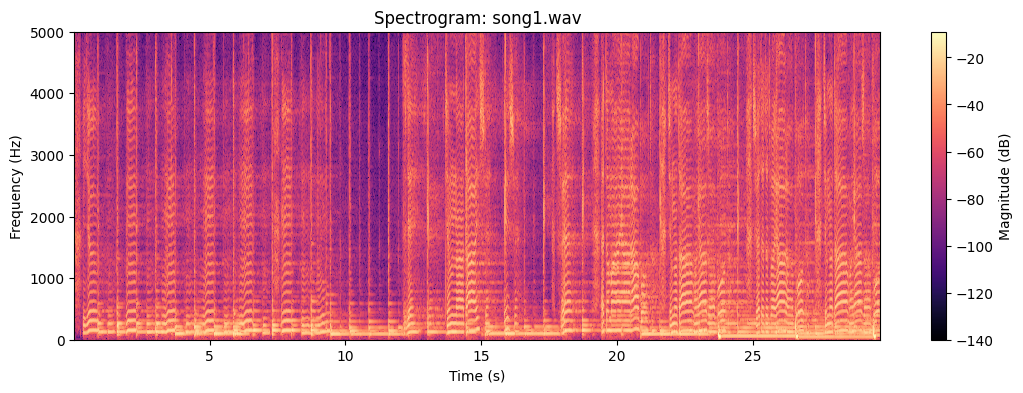

In [12]:
def make_spectrogram(samples, rate=SAMPLE_RATE):
    nperseg = max(128, int(WINDOW_SECONDS * rate))
    noverlap = max(0, nperseg - int(HOP_SECONDS * rate))
    freqs, times, spectrum = signal.stft(
        samples, fs=rate, window="hann",
        nperseg=nperseg, noverlap=noverlap,
        nfft=4 * nperseg, boundary=None
    )
    magnitude_db = 20 * np.log10(np.maximum(np.abs(spectrum), 1e-7))
    return freqs, times, magnitude_db

wav_files = sorted(LIBRARY_DIR.glob("*.wav"))
if wav_files:
    demo_rate, demo_audio = read_audio(wav_files[0])
    demo_freqs, demo_times, demo_db = make_spectrogram(demo_audio, demo_rate)
    plt.figure(figsize=(13, 4))
    plt.pcolormesh(demo_times, demo_freqs, demo_db, shading="auto", cmap="magma")
    plt.ylim(0, min(5000, demo_rate / 2))
    plt.xlabel("Time (s)")
    plt.ylabel("Frequency (Hz)")
    plt.title(f"Spectrogram: {wav_files[0].name}")
    plt.colorbar(label="Magnitude (dB)")
    plt.show()
else:
    print("No WAV files found yet.")

## 4. Select spectral landmarks

A landmark is a local maximum in the time-frequency plane. This notebook uses a maximum filter to find local peaks, then limits their density by retaining strong candidates within small time slices.

The paper's key idea is to keep a sparse constellation of reproducible peaks. The exact peak-selection settings here are implementation choices for this demo, not claimed to be Shazam's original parameters.

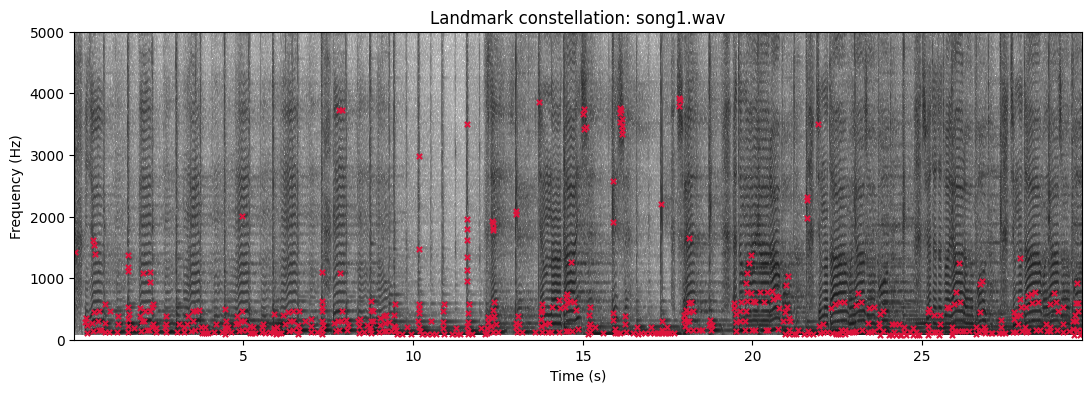

Landmarks extracted: 540


In [13]:
def find_landmarks(samples, rate=SAMPLE_RATE):
    freqs, times, db = make_spectrogram(samples, rate)

    # Ignore the very lowest bins, which are often dominated by rumble/DC.
    valid_freq = freqs >= 80
    freqs = freqs[valid_freq]
    db = db[valid_freq, :]

    local_max = signal.maximum_filter if hasattr(signal, "maximum_filter") else None
    # scipy.ndimage supplies the multidimensional maximum filter.
    from scipy.ndimage import maximum_filter
    neighborhood = maximum_filter(db, size=PEAK_NEIGHBORHOOD, mode="nearest")
    peak_mask = (db == neighborhood)

    # Relative threshold avoids selecting extremely quiet bins.
    threshold = np.percentile(db, 72)
    rows, cols = np.where(peak_mask & (db >= threshold))

    candidates = [(int(c), int(r), float(db[r, c])) for r, c in zip(rows, cols)]

    # Keep only the strongest few candidates per short time slice.
    slice_width = max(1, int(round(1.0 / max(HOP_SECONDS, 1e-3))))
    chosen = []
    grouped = defaultdict(list)
    for col, row, strength in candidates:
        grouped[col // slice_width].append((col, row, strength))

    for group in grouped.values():
        group.sort(key=lambda item: item[2], reverse=True)
        chosen.extend(group[:MAX_PEAKS_PER_SECOND])

    # Store (time_seconds, frequency_bin, frequency_hz).
    landmarks = []
    for col, row, _ in chosen:
        landmarks.append((float(times[col]), int(row), float(freqs[row])))

    landmarks.sort(key=lambda item: item[0])
    return freqs, times, db, landmarks


if wav_files:
    f_axis, t_axis, db_axis, points = find_landmarks(demo_audio, demo_rate)
    plt.figure(figsize=(13, 4))
    plt.pcolormesh(t_axis, f_axis, db_axis, shading="auto", cmap="gray_r")
    if points:
        plt.scatter([p[0] for p in points], [p[2] for p in points],
                    s=14, marker="x", color="crimson")
    plt.ylim(0, min(5000, demo_rate / 2))
    plt.xlabel("Time (s)")
    plt.ylabel("Frequency (Hz)")
    plt.title(f"Landmark constellation: {wav_files[0].name}")
    plt.show()
    print(f"Landmarks extracted: {len(points)}")
else:
    print("Landmark plot will appear once audio files are added.")

## 5. Pair landmarks into fingerprints

For each anchor landmark, pair it with several landmarks a short time later. A fingerprint encodes the anchor frequency, target frequency, and time separation.

Because absolute time is excluded from the fingerprint, the same local musical passage can be found even when the query excerpt starts later in the original recording. We keep the anchor time separately for alignment during search.

In [14]:
def make_fingerprints(landmarks):
    fingerprints = []
    if not landmarks:
        return fingerprints

    for i, (anchor_time, anchor_bin, anchor_hz) in enumerate(landmarks):
        targets = []
        for target_time, target_bin, target_hz in landmarks[i + 1:]:
            delta = target_time - anchor_time
            if delta > TARGET_MAX_DT:
                break
            if delta >= TARGET_MIN_DT:
                targets.append((target_time, target_bin, target_hz, delta))

        # Nearby targets are enough for this small prototype.
        for target_time, target_bin, target_hz, delta in targets[:TARGET_FANOUT]:
            # Quantization reduces sensitivity to tiny numerical differences.
            key = (int(round(anchor_hz / 10)),
                   int(round(target_hz / 10)),
                   int(round(delta / 0.01)))
            fingerprints.append((key, anchor_time))

    return fingerprints


if wav_files:
    sample_fingerprints = make_fingerprints(points)
    print("Fingerprints generated:", len(sample_fingerprints))
    print("Example fingerprint and anchor time:", sample_fingerprints[:5])
else:
    print("Fingerprint examples will appear after adding audio files.")

Fingerprints generated: 2997
Example fingerprint and anchor time: [((142, 29, 31), 0.03297052154195011), ((142, 35, 34), 0.03297052154195011), ((142, 11, 35), 0.03297052154195011), ((142, 23, 36), 0.03297052154195011), ((29, 27, 19), 0.34226757369614513)]


## 6. Index the music collection

The index maps each fingerprint key to the track and the anchor time at which it occurs. An inverted index makes a query efficient: look up only entries for hashes present in the recording, instead of comparing every audio sample directly.

For a first experiment, use a small library of tracks and excerpts cut from those same files.

In [15]:
def build_index(folder=LIBRARY_DIR):
    index = defaultdict(list)
    track_names = {}
    track_count = 0

    for track_id, path in enumerate(sorted(folder.glob("*.wav"))):
        try:
            rate, audio = read_audio(path)
            landmarks = find_landmarks(audio, rate)[-1]
            fingerprints = make_fingerprints(landmarks)
        except Exception as exc:
            print(f"Skipping {path.name}: {exc}")
            continue

        track_names[track_id] = path.name
        for key, anchor_time in fingerprints:
            index[key].append((track_id, anchor_time))
        track_count += 1

    return index, track_names

fingerprint_index, track_names = build_index()
print(f"Indexed tracks: {len(track_names)}")
print(f"Distinct fingerprint keys: {len(fingerprint_index)}")

/tmp/ipykernel_4781/3557167635.py:2: WavFileWarning: Reached EOF prematurely; finished at 10485760 bytes, expected 17603356 bytes from header.
  rate, raw = wavfile.read(str(path))


Indexed tracks: 1
Distinct fingerprint keys: 5669


## 7. Search with offset agreement

A shared fingerprint is a candidate match, but one shared key can occur by chance. For each hit, compute:

`offset = track_anchor_time - query_anchor_time`

When the query comes from a track in the library, many correct hits should vote for approximately the same offset. We rank candidates by their strongest offset bin. The binning and score are deliberately simple; production systems need more careful confidence calibration and false-positive testing.

In [16]:
def recognize(query_audio, query_rate=SAMPLE_RATE, index=None, names=None, bin_width=0.10):
    if index is None:
        index = fingerprint_index
    if names is None:
        names = track_names

    query_points = find_landmarks(query_audio, query_rate)[-1]
    query_fingerprints = make_fingerprints(query_points)
    votes = defaultdict(Counter)

    for key, query_time in query_fingerprints:
        for track_id, track_time in index.get(key, []):
            offset = track_time - query_time
            offset_bin = int(round(offset / bin_width))
            votes[track_id][offset_bin] += 1

    ranked = []
    for track_id, histogram in votes.items():
        if histogram:
            best_bin, best_count = histogram.most_common(1)[0]
            ranked.append({
                "track": names[track_id],
                "track_id": track_id,
                "aligned_hits": best_count,
                "estimated_offset_seconds": best_bin * bin_width,
                "all_hits": sum(histogram.values())
            })

    ranked.sort(key=lambda row: (row["aligned_hits"], row["all_hits"]), reverse=True)
    return ranked, query_fingerprints


def show_results(ranked, limit=5):
    if not ranked:
        print("No convincing candidate found. Try a longer excerpt or add more indexed audio.")
        return
    print(f"{'Rank':<6}{'Track':<32}{'Aligned hits':<16}{'Offset (s)':<12}")
    print("-" * 66)
    for rank, result in enumerate(ranked[:limit], start=1):
        print(f"{rank:<6}{result['track'][:30]:<32}{result['aligned_hits']:<16}{result['estimated_offset_seconds']:<12.2f}")

## 8. Try a query excerpt

Choose one of the library files and take a short crop from somewhere after the beginning. The crop is treated as an unknown query. If the index has been built correctly, the source track should rank highly.

Change `QUERY_START` and `QUERY_LENGTH` to test different portions of the track.

In [17]:
if wav_files and track_names:
    query_path = wav_files[0]
    query_rate, full_track = read_audio(query_path)

    QUERY_START = min(12.0, max(0.0, len(full_track) / query_rate * 0.35))
    QUERY_LENGTH = 6.0
    start_idx = int(QUERY_START * query_rate)
    end_idx = min(len(full_track), start_idx + int(QUERY_LENGTH * query_rate))
    query_clip = full_track[start_idx:end_idx]

    ranked_matches, query_fp = recognize(query_clip, query_rate)
    print(f"Query source used for this controlled test: {query_path.name}")
    print(f"Query length: {len(query_clip) / query_rate:.2f} seconds")
    show_results(ranked_matches)
else:
    print("Add at least one WAV file to music_library/ and rerun the indexing and query cells.")

/tmp/ipykernel_4781/3557167635.py:2: WavFileWarning: Reached EOF prematurely; finished at 10485760 bytes, expected 17603356 bytes from header.
  rate, raw = wavfile.read(str(path))


Query source used for this controlled test: song1.wav
Query length: 6.00 seconds
Rank  Track                           Aligned hits    Offset (s)  
------------------------------------------------------------------
1     song1.wav                       161             12.00       


## 9. Evaluate instead of guessing

A useful resume project reports measured results rather than assuming that a score means a particular percentage of confidence. Try multiple excerpts from different tracks, and record whether the correct source appears at rank 1.

For a more meaningful evaluation, make test excerpts from positions not used as separate database files, and optionally add noise at controlled levels. Avoid evaluating only on the exact same complete file as the query.

In [18]:
def add_white_noise(audio, snr_db, rng_seed=7):
    rng = np.random.default_rng(rng_seed)
    audio = np.asarray(audio, dtype=np.float32)
    signal_power = np.mean(audio ** 2) + 1e-12
    noise = rng.normal(size=len(audio)).astype(np.float32)
    noise_power = np.mean(noise ** 2) + 1e-12
    target_noise_power = signal_power / (10 ** (snr_db / 10))
    return audio + noise * np.sqrt(target_noise_power / noise_power)


# Optional noise experiment on the current query:
if wav_files and len(query_clip):
    noisy_clip = add_white_noise(query_clip, snr_db=5)
    noisy_ranked, _ = recognize(noisy_clip, query_rate)
    print("Top candidates for query with added noise (SNR = 5 dB):")
    show_results(noisy_ranked)

Top candidates for query with added noise (SNR = 5 dB):
Rank  Track                           Aligned hits    Offset (s)  
------------------------------------------------------------------
1     song1.wav                       45              12.00       


## 10. Interpretation and limitations

- **Fingerprinting is not musical understanding.** The method recognizes local acoustic structure already represented in the library; it does not identify a melody from humming.
- **Peak selection matters.** Too few peaks create too few matching opportunities; too many increase storage and accidental matches.
- **Offset agreement is the key evidence.** A candidate with many hashes but no consistent offset should be treated cautiously.
- **This notebook is a baseline.** It omits production-scale storage, carefully calibrated false-positive thresholds, robust handling of many audio formats, and extensive benchmark datasets.

### Reference

Wang, Avery Li-Chun. “An Industrial-Strength Audio Search Algorithm.” *Proceedings of the International Conference on Music Information Retrieval (ISMIR)*, 2003. The paper's relevant ideas are robust spectrogram constellations, combinatorial hashing, and matching by temporal-offset clusters.

The notebook's parameter choices and implementation details are a simplified educational adaptation, not a claim to reproduce Shazam's proprietary production implementation.